In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder,OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
data = {
    'Study': ['Low', 'High', 'Medium', 'High', 'Low',
              'Medium', 'High', 'Low', 'Medium', 'High',
              'Low', 'Medium', 'High', 'Medium', 'Low',
              'High', 'Medium', 'Low', 'High', 'Medium'],

    'Attendance': ['Poor', 'Good', 'Average', 'Good', 'Poor',
                   'Average', 'Good', 'Poor', 'Average', 'Good',
                   'Poor', 'Average', 'Good', 'Average', 'Poor',
                   'Good', 'Average', 'Poor', 'Good', 'Average'],

    'Assignment': ['No', 'Yes', 'Yes', 'Yes', 'No',
                   'Yes', 'Yes', 'No', 'No', 'Yes',
                   'No', 'Yes', 'Yes', 'No', 'No',
                   'Yes', 'Yes', 'No', 'Yes', 'Yes'],

    'Result': ['Fail', 'Pass', 'Pass', 'Pass', 'Fail',
               'Pass', 'Pass', 'Fail', 'Fail', 'Pass',
               'Fail', 'Pass', 'Pass', 'Fail', 'Fail',
               'Pass', 'Pass', 'Fail', 'Pass', 'Pass']
}

df = pd.DataFrame(data)
print(df.head())

    Study Attendance Assignment Result
0     Low       Poor         No   Fail
1    High       Good        Yes   Pass
2  Medium    Average        Yes   Pass
3    High       Good        Yes   Pass
4     Low       Poor         No   Fail


In [3]:
X  = df.drop(columns = ['Result'] , axis = 1)
y =  df['Result']
le =  LabelEncoder()

x_train , x_test,y_train , y_test = train_test_split(X,y,test_size= 0.2)

In [18]:
# le =  LabelEncoder()

# for col in x_train.columns:
#     if not pd.api.types.is_numeric_dtype(x_train[col]):
#         x_train[col] = le.fit_transform(x_train[col])
#         x_test[col] =  le.transform(x_test[col]) 

oe = OrdinalEncoder(categories=[
    ['Low','Medium','High'],
    ['Poor','Average','Good'],
    ['No','Yes']
])
from sklearn.preprocessing  import OrdinalEncoder


cat_cols = []

for col in x_train.columns:
    if not pd.api.types.is_numeric_dtype(x_train[col]):
        print(df[col].dtype)
        cat_cols.append(col)
        print(col)


object
Study
object
Attendance
object
Assignment


In [19]:
x_train[cat_cols]

,Study,Attendance,Assignment
1,High,Good,Yes
3,High,Good,Yes
11,Medium,Average,Yes
4,Low,Poor,No
16,Medium,Average,Yes
9,High,Good,Yes
6,High,Good,Yes
2,Medium,Average,Yes
13,Medium,Average,No
19,Medium,Average,Yes


In [20]:
x_train[cat_cols] =  oe.fit_transform(x_train[cat_cols])
x_test[cat_cols] = oe.transform(x_test[cat_cols])

In [22]:
model = CategoricalNB()

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print("Predictions:", y_pred)

Predictions: ['Pass' 'Fail' 'Pass' 'Pass']


Accuracy: 1.0


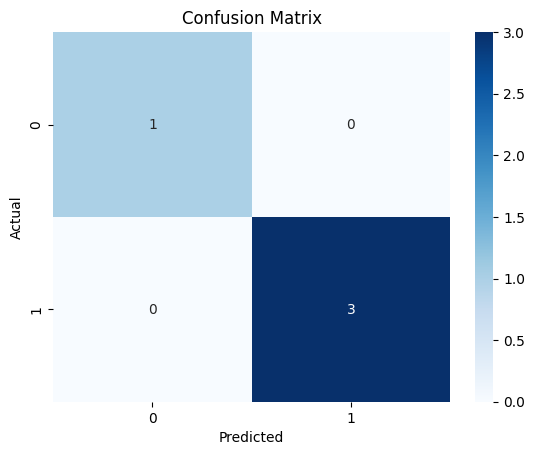

              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         3

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4



In [23]:
print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred))